# 11 &nbsp;A better comparison: synthetic control

**Where notebook 10 left off.** Difference-in-differences compared California with the average of 38 other states, and that average was a poor match: California was already pulling away before the policy.

**The idea.** Instead of the plain average, build a **synthetic California**: a weighted blend of other states, chosen so that the blend's cigarette sales track California's as closely as possible from 1970 to 1988. Weights can't be negative and must add up to one, so the blend is always a mix of real states, not an extrapolation. If the blend tracks California closely for 19 years before the policy, the gap after 1988 is a credible estimate of what the policy did.

**How to trust it with one treated state.** There is no sample of treated states to compute a standard error from. So the method is run again with every other state pretending to have passed the policy. If California's gap is unusual among those placebos, the effect is real.

In [1]:
import numpy as np
import pandas as pd

from exptoolkit import plots, style
from exptoolkit.causal import did, load_smoking, synth_placebos, synthetic_control

style.use_style()
panel = load_smoking()
treated, start = "California", 1989
result = synthetic_control(panel, treated, start)

## 1. Which states make up synthetic California?

In [2]:
weights = result.weights[result.weights > 0.005].sort_values(ascending=False)
weights.rename("Weight").to_frame().style.format("{:.0%}")

,Weight
state,
Utah,39%
Montana,23%
Nevada,20%
Connecticut,11%
New Hampshire,5%
Colorado,1%


In [3]:
print(f"Average miss before 1989: {result.pre_rmspe:.1f} packs per person per year")

Average miss before 1989: 1.7 packs per person per year


Six states make up the blend, led by Utah, Montana and Nevada. Before 1989 the blend misses California by under 2 packs a year on average, against about 24 packs for the plain average of all other states in 1988.

## 2. The effect

Average effect 1989 to 2000: -19.5 packs per person per year
Effect in 2000: -26.6 packs per person


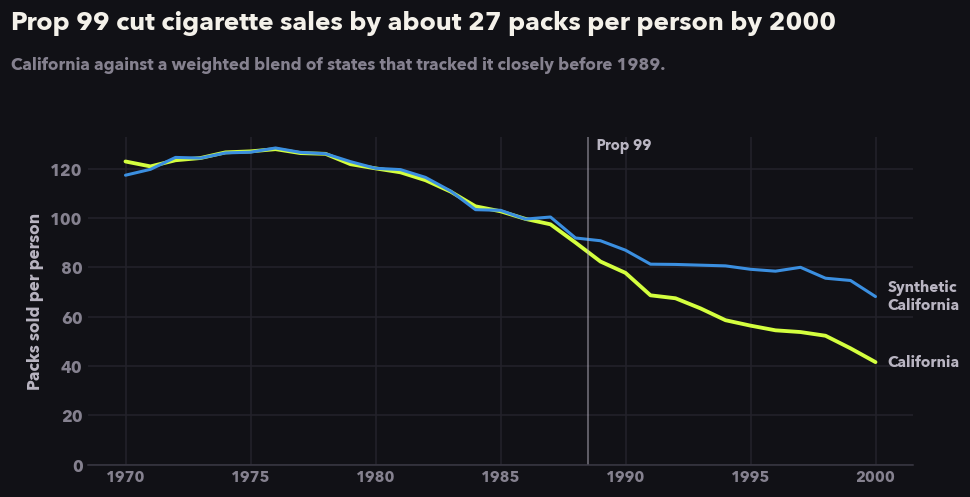

In [4]:
gap_2000 = result.gap.loc[2000]
fig, ax = plots.trend_plot({"California": (result.actual, "treated"),
                           "Synthetic\nCalifornia": (result.synthetic, "synthetic")}, start, "Packs sold per person")
style.headline(fig, f"Prop 99 cut cigarette sales by about {-gap_2000:.0f} packs per person by 2000",
               "California against a weighted blend of states that tracked it closely before 1989.")
style.save(fig, "synthetic_control")
print(f"Average effect 1989 to 2000: {result.average_effect:.1f} packs per person per year")
print(f"Effect in 2000: {gap_2000:.1f} packs per person")

The two lines sit on top of each other for 19 years, then split as soon as the policy starts. By 2000, Californians bought about 27 fewer packs per person than the blend suggests they would have. The original study reports about 26, using extra predictors such as income and beer consumption; this version matches on cigarette sales alone and lands in the same place.

## 3. Is the gap unusual? Placebo states

Run the same method for every other state as if it had passed Prop 99 in 1989. States whose synthetic version can't track them before 1989 (a pre-1989 miss more than five times California's) are left out, because their post-1989 gaps say nothing.

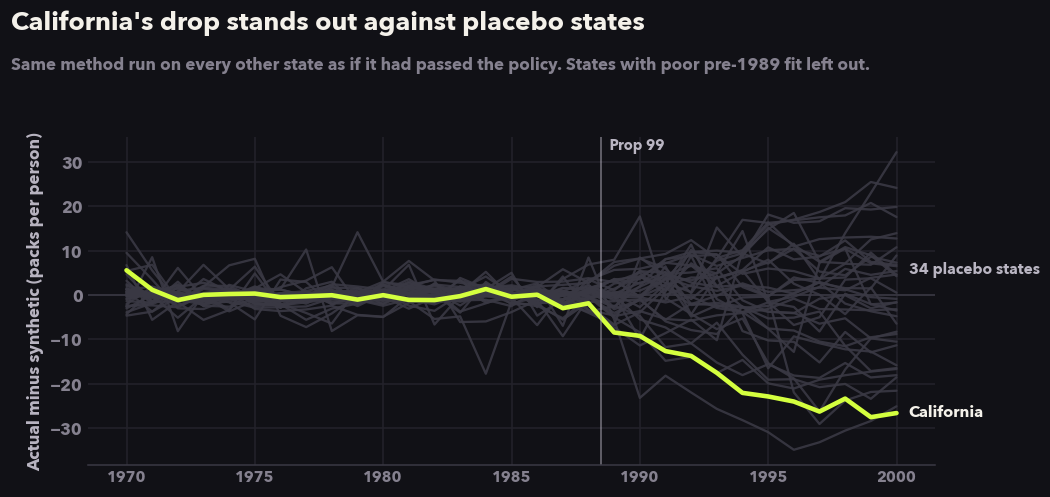

In [5]:
placebos = synth_placebos(panel, treated, start)
good = {u: r for u, r in placebos.items() if r.pre_rmspe <= 5 * result.pre_rmspe}
fig, ax = plots.placebo_gaps_plot(result, good, start)
style.headline(fig, "California's drop stands out against placebo states",
               "Same method run on every other state as if it had passed the policy. States with poor pre-1989 fit left out.")
style.save(fig, "placebo_gaps")

In [6]:
effects = pd.Series({u: r.average_effect for u, r in good.items()})
bigger = int((effects.abs() >= abs(result.average_effect)).sum())
ratios = pd.Series({u: r.ratio for u, r in placebos.items()} | {treated: result.ratio}).sort_values(ascending=False)
rank = int(ratios.index.get_loc(treated)) + 1
print(f"Placebo states with a good pre-1989 fit: {len(good)}")
print(f"Placebos with an average effect at least as large as California's: {bigger}")
print(f"  -> permutation p-value: {(bigger + 1) / (len(good) + 1):.3f}")
print(f"California's rank by post/pre misfit ratio: {rank} of {len(ratios)}  (p = {rank / len(ratios):.3f})")

Placebo states with a good pre-1989 fit: 34
Placebos with an average effect at least as large as California's: 1
  -> permutation p-value: 0.057
California's rank by post/pre misfit ratio: 3 of 39  (p = 0.077)


Only one of the well-fitting placebo states shows an average effect as large as California's. Ranked by how much the fit breaks after 1989 relative to before, California comes third of 39. Both point the same way, with honest limits. An effect this size is rare among the placebo states (p-values of about 0.06 and 0.08), and with only 39 states the smallest p-value possible is about 0.03. Together with the close fit and the robustness checks below, that is good evidence, not proof.

## 4. Robustness

Two checks that a skeptical reader would ask for:

- **Leave one out.** Drop each heavily weighted donor state in turn and rebuild the blend. If the answer hinges on one state, it is fragile.
- **Placebo in time.** Pretend the policy started in 1981, using only data before the real policy. A sound method should find little or nothing. Difference-in-differences found about 12 packs here.

In [7]:
top = result.weights[result.weights > 0.05].index
loo = pd.Series({f"Without {u}": synthetic_control(panel.drop(columns=u), treated, start).average_effect for u in top})
fake = synthetic_control(panel.loc[:1988], treated, 1981)
print("Leave one out, average effect 1989 to 2000:")
print(loo.round(1).to_string())
print(f"\nFake 1981 policy, average 'effect' 1981 to 1988: {fake.average_effect:.1f} packs per person")

Leave one out, average effect 1989 to 2000:
Without Connecticut   -20.5
Without Montana       -18.0
Without Nevada        -19.2
Without Utah          -19.1

Fake 1981 policy, average 'effect' 1981 to 1988: -3.3 packs per person


## 5. Both methods side by side

In [8]:
pd.DataFrame({
    "Average effect 1989 to 2000": [did(panel, treated, start), result.average_effect],
    "Fake-policy check": ["About 12 packs from a fake 1980 policy", f"About {abs(fake.average_effect):.0f} packs from a fake 1981 policy"],
    "Pre-1989 match": ["Poor: California already diverging", f"Close: misses by {result.pre_rmspe:.1f} packs a year"],
}, index=["Difference-in-differences", "Synthetic control"]).style.format(
    {"Average effect 1989 to 2000": "{:.1f} packs"})

,Average effect 1989 to 2000,Fake-policy check,Pre-1989 match
Difference-in-differences,-27.3 packs,About 12 packs from a fake 1980 policy,Poor: California already diverging
Synthetic control,-19.5 packs,About 3 packs from a fake 1981 policy,Close: misses by 1.7 packs a year


## What this tells us

- **Prop 99 worked.** Cigarette sales in California fell about **20 packs per person per year** more than they otherwise would have over 1989 to 2000, reaching about **27 packs** by 2000.
- **Difference-in-differences overstated it by about 40%** (27 packs a year against about 20), because it credited the policy with a trend that had started years earlier. Synthetic control removes most of that: its fake-policy check finds only a few packs.
- **The answer survives the obvious challenges.** Dropping any one key donor state moves the estimate by about a pack or two, and few placebo states show anything like it.

**What it can't tell us.** One state, one policy: this says what Prop 99 did in California, not what a tax would do elsewhere. The tax and the anti-smoking programs came together, so their separate effects can't be pulled apart. And packs *sold* in California is not packs *smoked*: some buying may have moved across state lines.

**The general habit:** when you can't randomize, spend the effort on the comparison group, then attack it with placebos in time and in space before you believe the number.